# Visualisation — Final Figures for the Project Summary

Reads outputs saved by the four earlier notebooks and produces polished figures,
saved to `references/figures/`. Run the other notebooks first, in order:
`data_processing` → `data_exploratory_analysis` → `train_model` → `predict_model`.

## 1. Imports and Load Saved Outputs

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os

sns.set_theme(style="whitegrid", context="talk")

FIGURE_DIR = "../../references/figures"
os.makedirs(FIGURE_DIR, exist_ok=True)

df = pd.read_csv("../../data/processed/employee_processed.csv")
dept_summary = pd.read_csv("../../data/processed/department_performance.csv", index_col=0)
assoc = pd.read_csv("../../data/processed/eda_association_summary.csv")
comparison = pd.read_csv("../../data/processed/model_comparison_full.csv")
importance = pd.read_csv("../../data/processed/permutation_importance.csv")
predictions = pd.read_csv("../../data/processed/test_predictions_full.csv")
scores = pd.read_csv("../../data/processed/employee_support_priority_scores.csv")
threshold_table = pd.read_csv("../../data/processed/threshold_tradeoff.csv")
metrics = json.load(open("../../data/processed/model_metrics.json"))

TARGET = "PerformanceRating"

def finish(name):
    plt.tight_layout()
    plt.savefig(f"{FIGURE_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("All files loaded.")

All files loaded.


## Figure 1: Distribution of Performance Ratings

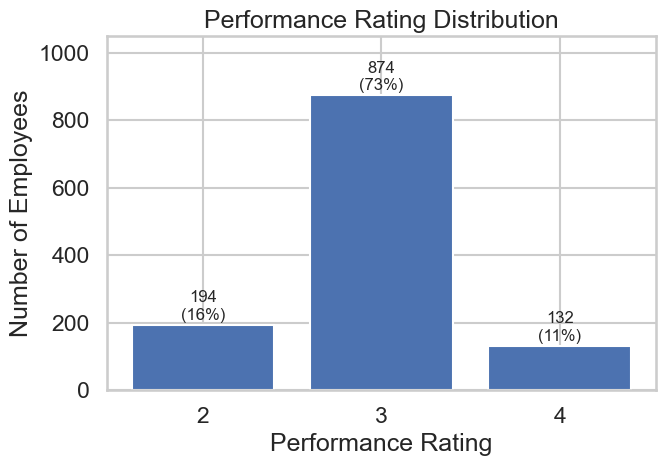

In [2]:
counts = df[TARGET].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(counts.index.astype(str), counts.values, color="#4C72B0")
for i, v in enumerate(counts.values):
    ax.text(i, v + 15, f"{v}\n({v/len(df):.0%})", ha="center", fontsize=12)
ax.set_xlabel("Performance Rating")
ax.set_ylabel("Number of Employees")
ax.set_title("Performance Rating Distribution")
ax.set_ylim(0, counts.max() * 1.2)
finish("01_rating_distribution")

*Ratings are heavily skewed toward "Excellent" (73%), motivating the use of macro F1 over accuracy.*

## Figure 2: Department-Wise Performance

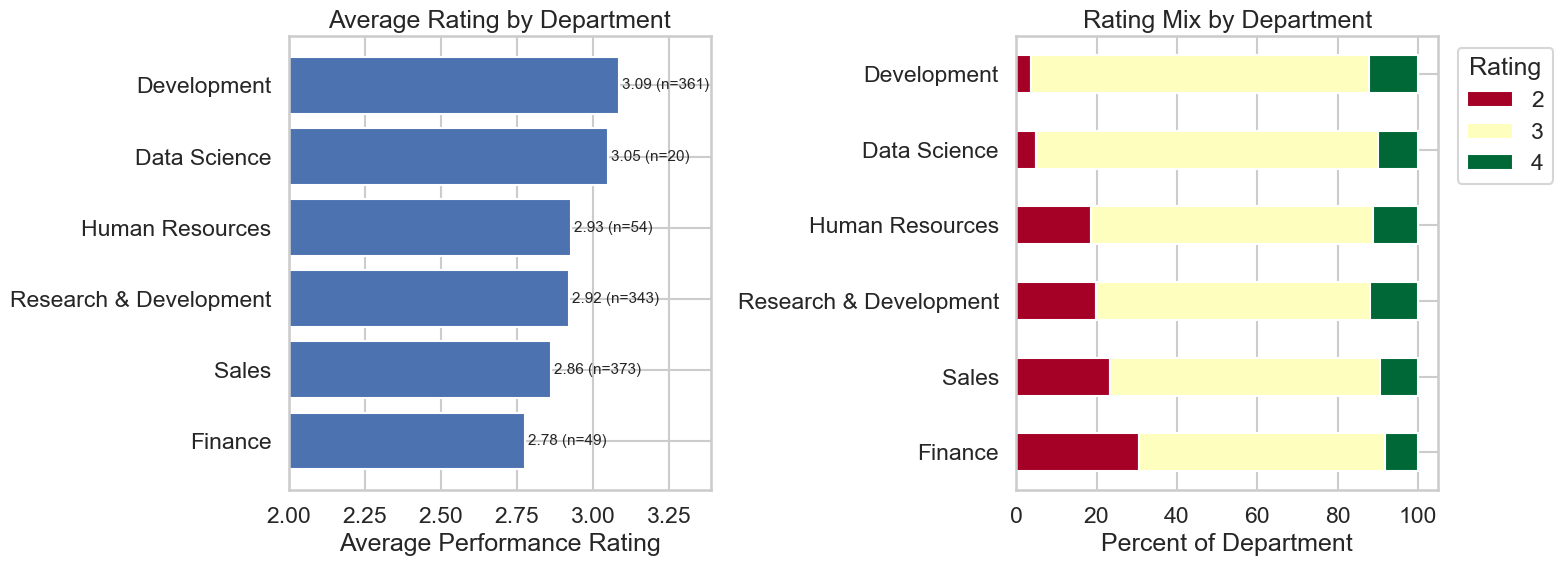

In [3]:
dept_order = dept_summary.sort_values("mean_rating").index

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: average rating by department
axes[0].barh(dept_order, dept_summary.loc[dept_order, "mean_rating"], color="#4C72B0")
for i, dept in enumerate(dept_order):
    m = dept_summary.loc[dept, "mean_rating"]
    n = dept_summary.loc[dept, "headcount"]
    axes[0].text(m + 0.01, i, f"{m:.2f} (n={n:.0f})", va="center", fontsize=11)
axes[0].set_xlim(2.0, dept_summary["mean_rating"].max() + 0.3)
axes[0].set_xlabel("Average Performance Rating")
axes[0].set_title("Average Rating by Department")

# Right: rating mix (stacked percentages)
shares = pd.crosstab(df["EmpDepartment"], df[TARGET], normalize="index").mul(100)
shares.loc[dept_order].plot(kind="barh", stacked=True, ax=axes[1], colormap="RdYlGn")
axes[1].set_xlabel("Percent of Department")
axes[1].set_ylabel("")
axes[1].set_title("Rating Mix by Department")
axes[1].legend(title="Rating", bbox_to_anchor=(1.02, 1))

finish("02_department_performance")

*Finance and Sales lag behind Development and Data Science, confirmed by a significant chi-square test (p < 0.0001).*

## Figure 3: Factor Association Ranking (Statistical)

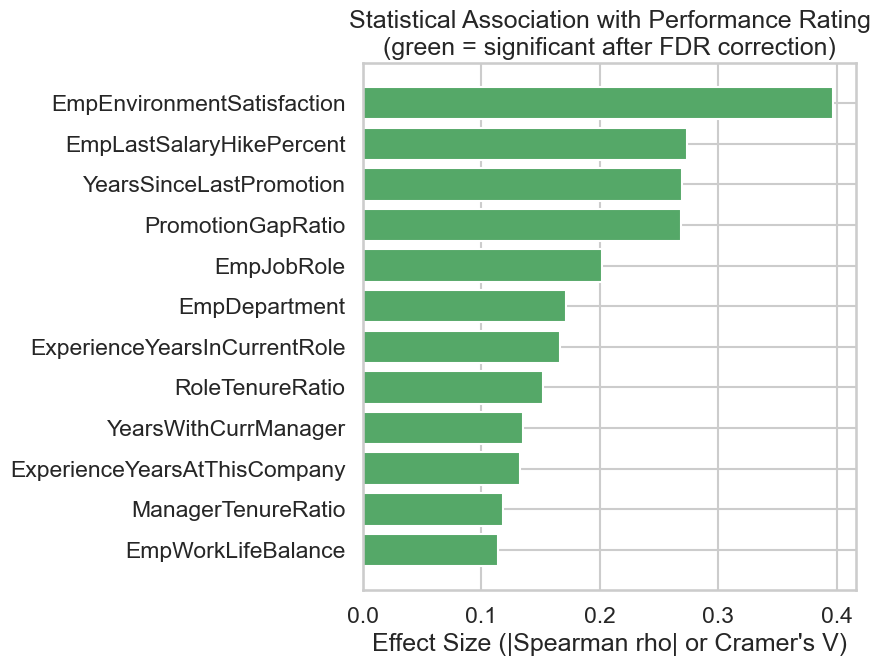

In [4]:
top = assoc.sort_values("effect_size", ascending=False).head(12).iloc[::-1]
colors = np.where(top["significant"], "#55A868", "#BBBBBB")

plt.figure(figsize=(9, 7))
plt.barh(top["factor"], top["effect_size"], color=colors)
plt.xlabel("Effect Size (|Spearman rho| or Cramer's V)")
plt.title("Statistical Association with Performance Rating\n(green = significant after FDR correction)")
finish("03_association_ranking")

*Environment satisfaction, salary hike, and the promotion/tenure cluster stand out as the leading statistically significant factors.*

## Figure 4: Algorithm Comparison (Cross-Validated Macro F1)

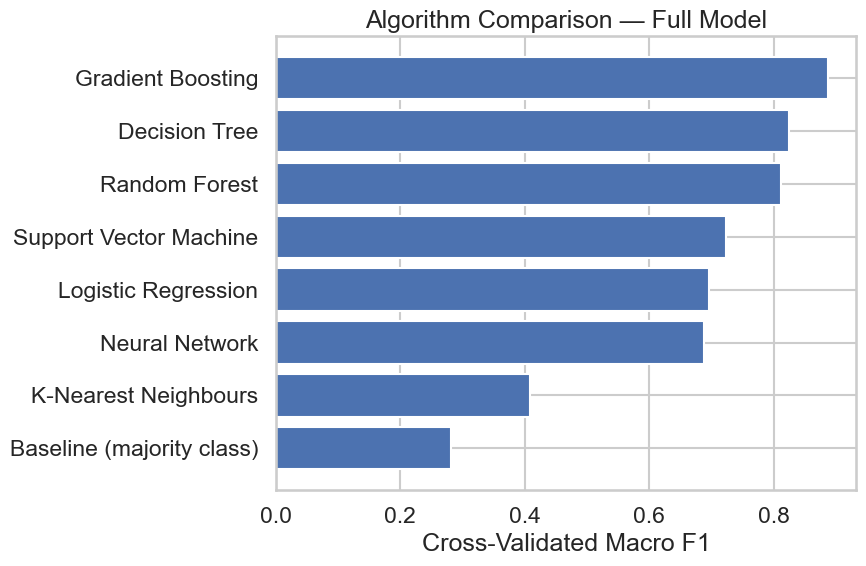

In [5]:
sub = comparison.sort_values("cv_macro_f1")

plt.figure(figsize=(9, 6))
plt.barh(sub["model"], sub["cv_macro_f1"], color="#4C72B0")
plt.xlabel("Cross-Validated Macro F1")
plt.title("Algorithm Comparison — Full Model")
finish("04_model_comparison")

*Gradient Boosting clearly outperforms all other algorithms tested.*

## Figure 5: Confusion Matrix — Full Model (Test Set)

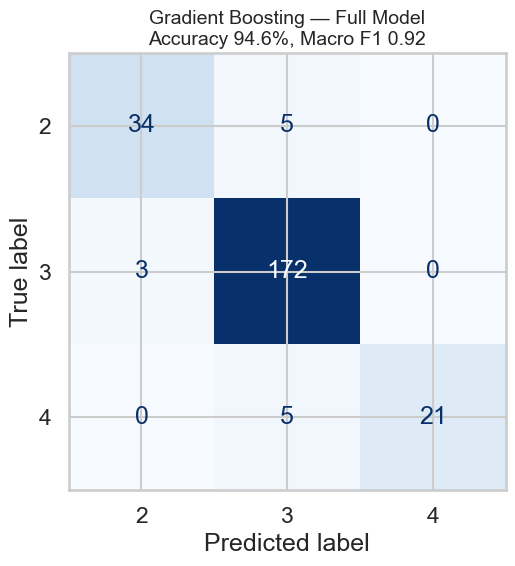

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6.5, 6))
ConfusionMatrixDisplay.from_predictions(
    predictions["actual"], predictions["predicted"], cmap="Blues", ax=ax, colorbar=False
)
acc = metrics["full"]["test_accuracy"]
f1 = metrics["full"]["test_macro_f1"]
ax.set_title(f"Gradient Boosting — Full Model\nAccuracy {acc:.1%}, Macro F1 {f1:.2f}", fontsize=14)
finish("05_confusion_matrix_full_model")

### Observations

- The tuned Gradient Boosting model reaches **94.6% accuracy and 0.92 macro F1** on
  the untouched test set.
- Almost all errors sit on the diagonal's immediate neighbours — the model never
  confuses a rating of 2 with a rating of 4, or vice versa (both off-diagonal corners
  are 0). Its mistakes are always "off by one" rather than wildly wrong.
- The main weak spot is rating 4 (Outstanding): 5 of 26 true "4"s were predicted as
  "3", giving it the lowest recall (81%) of the three classes — a natural consequence
  of rating 4 being the smallest class in the training data.

## Figure 6: Factor Importance (Permutation Importance)

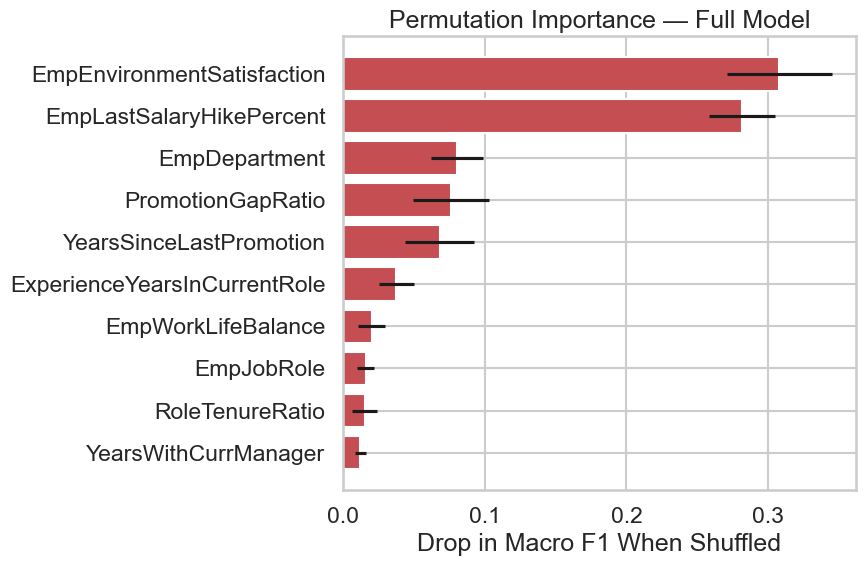

In [7]:
top10 = importance.head(10).iloc[::-1]

plt.figure(figsize=(9, 6))
plt.barh(top10["factor"], top10["importance_mean"], xerr=top10["importance_std"], color="#C44E52")
plt.xlabel("Drop in Macro F1 When Shuffled")
plt.title("Permutation Importance — Full Model")
finish("06_factor_importance")

### Observations

- `EmpEnvironmentSatisfaction` and `EmpLastSalaryHikePercent` are far ahead of every
  other factor — each causes roughly 3–4x the drop in macro F1 that the next-ranked
  factor does when shuffled.
- The remaining bars (`EmpDepartment`, `PromotionGapRatio`, `YearsSinceLastPromotion`,
  and other tenure-related columns) confirm the "career progression" theme identified
  in the exploratory analysis — several correlated columns each carrying a modest,
  individually-diluted share of the same underlying signal.

## Figure 7: Top 3 Factors vs Performance Rating

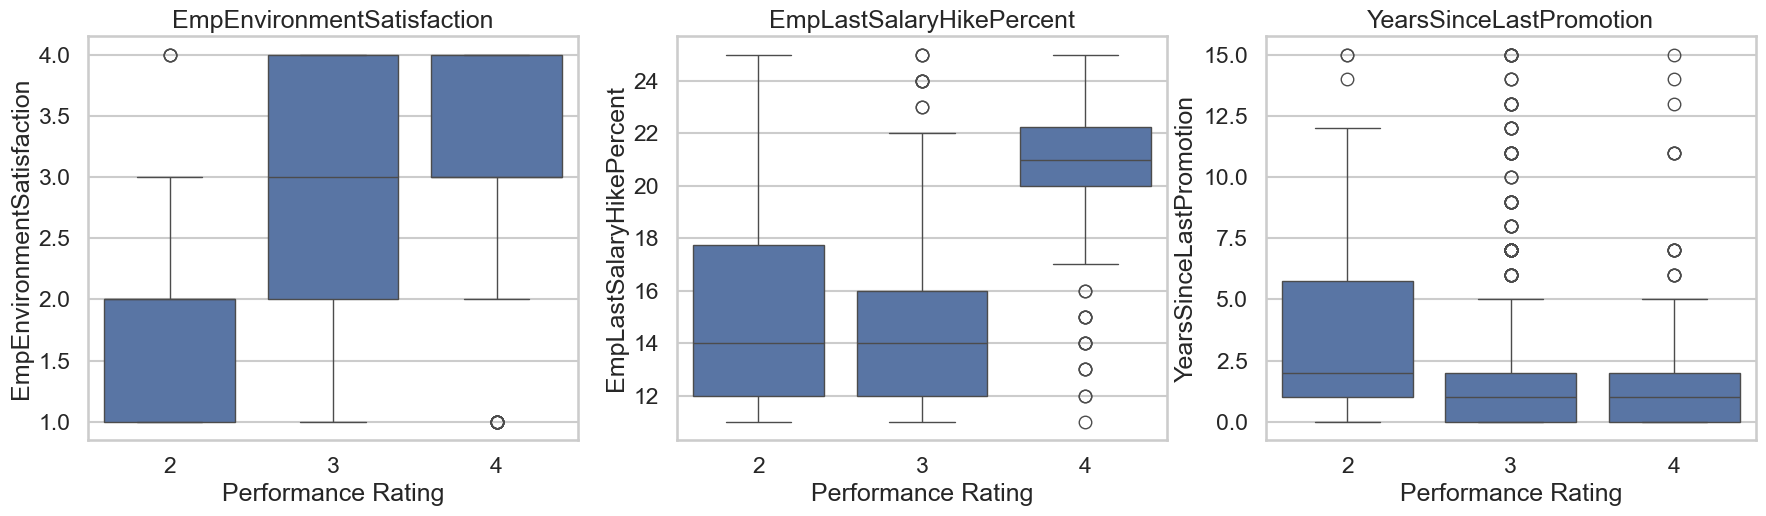

In [9]:
top3 = ["EmpEnvironmentSatisfaction", "EmpLastSalaryHikePercent", "YearsSinceLastPromotion"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, factor in zip(axes, top3):
    sns.boxplot(data=df, x=TARGET, y=factor, ax=ax, color="#4C72B0")
    ax.set_title(factor)
    ax.set_xlabel("Performance Rating")
finish("07_top_factor_relationships")

### Observations

- **Environment satisfaction** rises clearly from rating 2 to ratings 3–4 — low
  satisfaction is concentrated almost entirely among rating-2 employees.
- **Salary hike percent** shows the clearest separation of the three: rating-4
  employees received a visibly higher hike (median ~21%) than ratings 2 and 3
  (median ~14%), with little overlap.
- **Years since last promotion** is highest and most variable for rating-2 employees
  (median ~2 years, with outliers up to 15), and notably lower and tighter for ratings
  3 and 4 — consistent with the "promotion stagnation" pattern found earlier.

## Figure 8: Correlation Among Numeric Factors

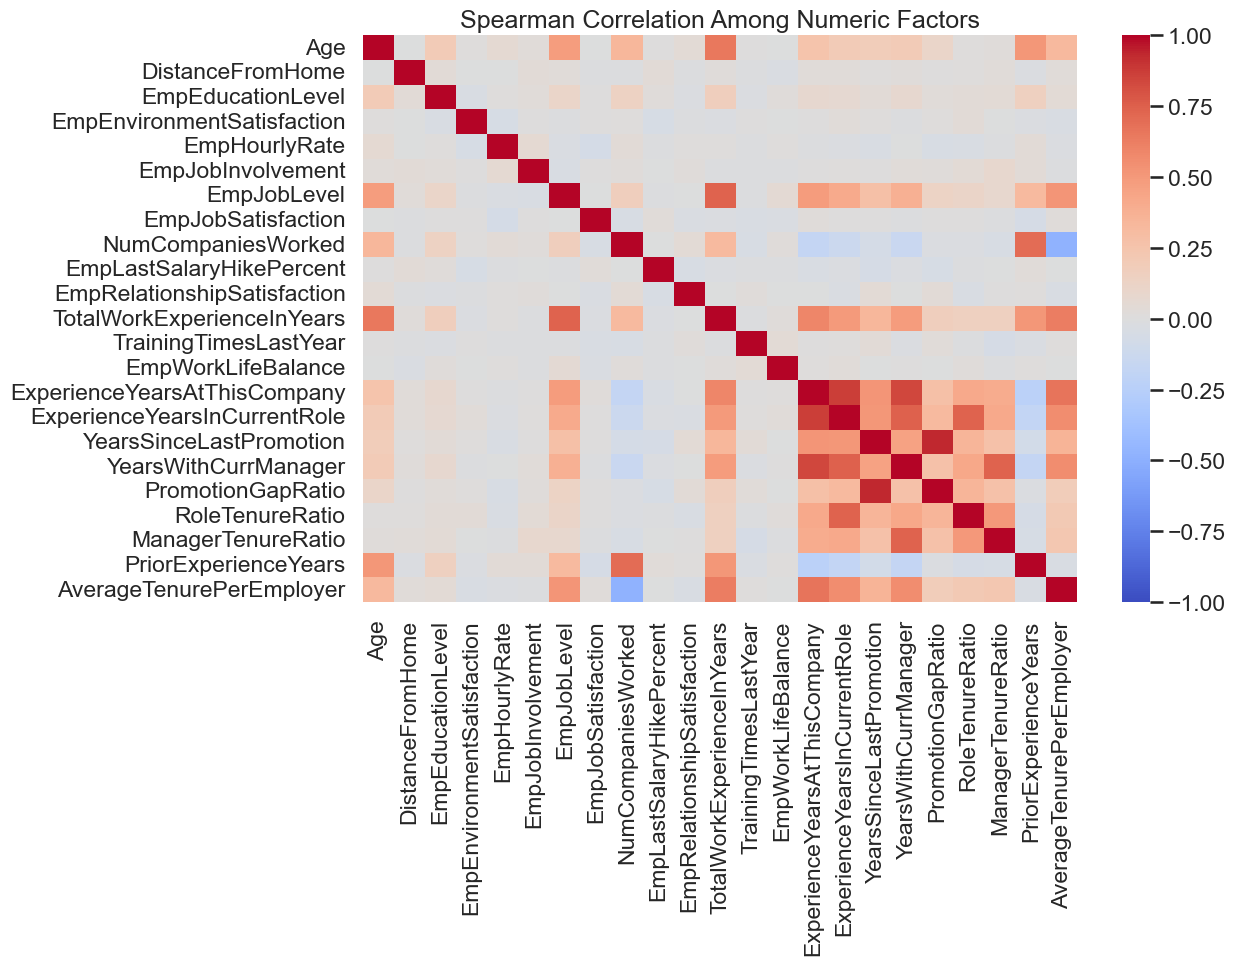

In [10]:
skip = {"EmpNumber", TARGET, "PerformanceLabel"}
numeric_cols = [c for c in df.select_dtypes("number").columns if c not in skip]

plt.figure(figsize=(13, 10))
sns.heatmap(df[numeric_cols].corr(method="spearman"), cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman Correlation Among Numeric Factors")
finish("08_correlation_heatmap")

### Observations

- The dark red block in the bottom-right corner confirms the tenure-related columns
  (`ExperienceYearsAtThisCompany`, `ExperienceYearsInCurrentRole`, `YearsSinceLastPromotion`,
  `YearsWithCurrManager`, and their ratio versions) are all strongly correlated with each
  other, exactly as found in the exploratory analysis (Section 5).
- Outside that block, correlations are weak — most factors, including the two strongest
  predictors (environment satisfaction, salary hike), vary largely independently of one
  another and of the tenure cluster.

## Figure 9: Support-Review Threshold Trade-off

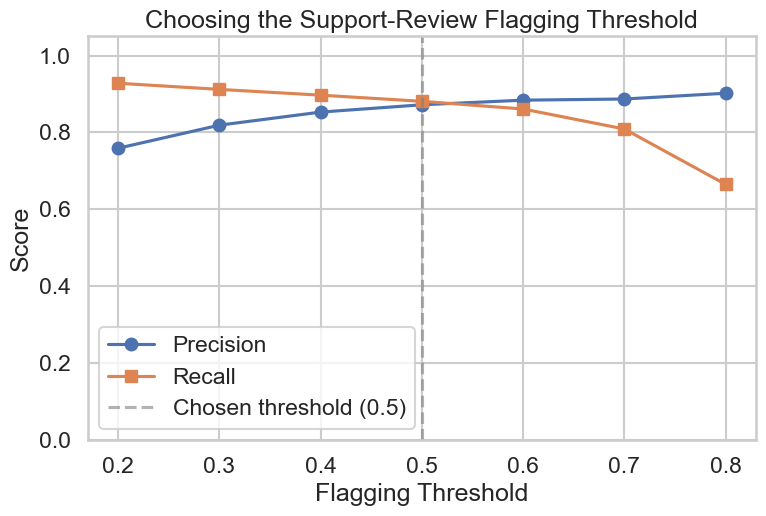

In [11]:
plt.figure(figsize=(8, 5.5))
plt.plot(threshold_table["threshold"], threshold_table["precision"], marker="o", label="Precision")
plt.plot(threshold_table["threshold"], threshold_table["recall"], marker="s", label="Recall")
plt.axvline(0.5, color="gray", linestyle="--", alpha=0.6, label="Chosen threshold (0.5)")
plt.xlabel("Flagging Threshold")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.legend()
plt.title("Choosing the Support-Review Flagging Threshold")
finish("09_threshold_tradeoff")

### Observations

- Precision and recall stay close together and both above 0.85 across a wide range of
  thresholds (0.4–0.6) — an unusually favourable trade-off, reflecting how strong the
  model's separation of classes is.
- The chosen threshold (0.5, dashed line) sits right where the two curves cross, giving
  a balanced 87% precision and 88% recall — 196 employees flagged (16% of the workforce),
  concentrated in Sales and Finance, satisfying the requirement to touch as few
  well-performing employees as possible while still catching the large majority of
  genuinely low-rated employees.

## Summary

Nine figures saved to `references/figures/`:

1. `01_rating_distribution.png` — class imbalance justifying macro F1
2. `02_department_performance.png` — department-wise performance (business question 1)
3. `03_association_ranking.png` — statistical factor ranking
4. `04_model_comparison.png` — algorithm comparison, Gradient Boosting selected
5. `05_confusion_matrix_full_model.png` — final model test performance
6. `06_factor_importance.png` — model-based top factors (business question 2)
7. `07_top_factor_relationships.png` — how the top 3 factors relate to rating
8. `08_correlation_heatmap.png` — multicollinearity among tenure variables
9. `09_threshold_tradeoff.png` — support-review flagging threshold (indicators of non-performers)

All five project notebooks are now complete:
`data_processing.ipynb` → `data_exploratory_analysis.ipynb` → `train_model.ipynb` →
`predict_model.ipynb` → `visualize.ipynb`.